# Métodos del mapa de investigación (versión sencilla)

Este notebook explica, con palabras sencillas, los métodos del mapa de investigación sobre monitoreo de puentes con teléfonos que van dentro de un carro (*drive-by*). Tiene los mismos métodos, en el mismo orden y con la misma numeración que la versión técnica: [research_map_methods.ipynb](research_map_methods.ipynb).

<a id="indice"></a>
## Índice

- [2 Modal identification](#modal-identification)
  - [2.2 Mode shapes](#mode-shapes)
    - [2.2.2 Signal decomposition](#mode-shapes-signal-decomposition)
      - [2.2.2.1 Wavelet transform (SSWT)](#wavelet-sswt)

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from ssqueezepy import Wavelet, ssq_cwt
from ssqueezepy.experimental import scale_to_freq

SEED = 42
rng = np.random.default_rng(SEED)

plt.rcParams.update({"figure.dpi": 100, "axes.grid": True, "grid.alpha": 0.3})

# Synthetic example (same as the technical notebook): a car crosses a 100 m bridge at 20 m/s
L = 100.0                               # bridge length, m
v = 20.0                                # car speed, m/s
f_mode = 1.3                            # bridge "note" (mode 2 frequency), Hz
fs = 100.0                              # sampling rate, Hz

t = np.arange(0, L / v, 1 / fs)         # time, s
pos = v * t                             # car position on the bridge, m
shape_true = np.sin(2 * np.pi * pos / L)  # how the bridge bends: up on one half, down on the other
x = np.abs(shape_true) * np.cos(2 * np.pi * f_mode * t) + 0.1 * rng.standard_normal(t.size)

# Wavelet maps: CWT (Wx) and synchrosqueezed SSWT (Tx), analytic Morlet wavelet
wavelet = Wavelet(("morlet", {"mu": 3}))
Tx, Wx, freqs_ssq, scales = ssq_cwt(x, wavelet, fs=fs, nv=32, padtype="zero")
freqs_cwt = scale_to_freq(scales, wavelet, N=2 ** 14, fs=fs)

---

<a id="modal-identification"></a>
## 2 Modal identification

---

<a id="mode-shapes"></a>
### 2.2 Mode shapes

<a id="mode-shapes-signal-decomposition"></a>
#### 2.2.2 Signal decomposition

<a id="wavelet-sswt"></a>
##### 2.2.2.1 Wavelet transform (SSWT)

*Versión técnica: [research_map_methods.ipynb, sección 2.2.2.1](research_map_methods.ipynb#wavelet-sswt)*

**Qué es**

- Es una herramienta que escucha una vibración y dice qué "notas" tiene y en qué momento suena cada una.
- Una "nota" es una frecuencia: cuántas veces por segundo se mueve algo de ida y vuelta.
- Analogía: es como una partitura. Fourier te dice qué notas hay en la canción completa; la wavelet además te dice en qué compás suena cada nota.

**Para qué sirve**

- Para vibraciones cortas o que cambian mientras se miden, como la de un carro que cruza un puente en pocos segundos.
- Con ella se puede ver cómo cambia la fuerza de una vibración del puente a medida que el carro avanza.
- Analogía: es como escuchar a alguien que pasa hablando frente a tu ventana. Solo lo oyes unos segundos, y su voz sube y baja mientras se acerca y se aleja.

**Cómo funciona**

1. Se toma una "onda de prueba": una pequeña vibración que empieza, oscila y se apaga, como el sonido de una campana.
2. Esa onda se hace más larga o más corta para probar cada nota (frecuencia).
3. Se va deslizando sobre la señal. Donde la señal vibra igual que la onda de prueba, "coinciden" y da un valor grande; donde no, da casi cero. Analogía: es como pasar un imán por la arena; solo se pegan las limaduras de hierro.
4. Con todos esos valores se arma un mapa de colores: el tiempo en un eje, las notas en el otro y el color indica qué tan fuerte suena cada nota en cada momento.

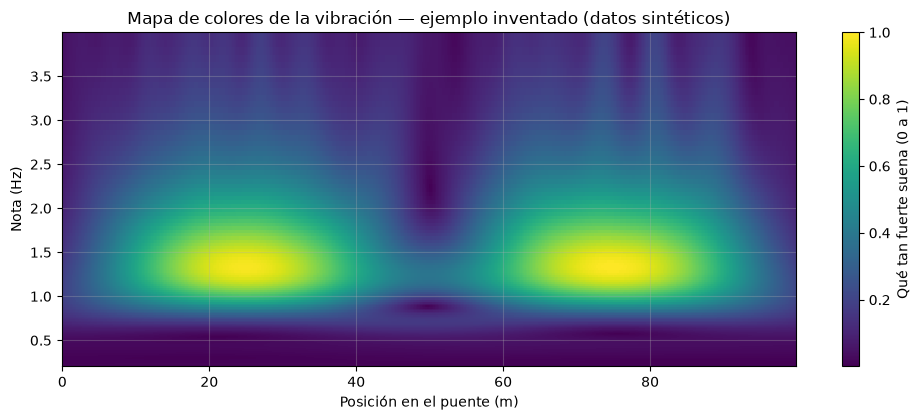

In [2]:
# Color map of the wavelet (CWT magnitude) versus car position
f_max = 4.0                                  # highest note shown, Hz
keep = freqs_cwt <= f_max
strength = np.abs(Wx[keep]) / np.abs(Wx).max()   # normalized: 1 = loudest

fig, ax = plt.subplots(figsize=(10, 4.3))
mesh = ax.pcolormesh(pos, freqs_cwt[keep], strength, shading="auto", cmap="viridis")
fig.colorbar(mesh, ax=ax, label="Qué tan fuerte suena (0 a 1)")
ax.set_xlabel("Posición en el puente (m)")
ax.set_ylabel("Nota (Hz)")
ax.set_title("Mapa de colores de la vibración — ejemplo inventado (datos sintéticos)")
fig.tight_layout()
plt.show()

**Figura 1.** Mapa de colores de una vibración inventada (ilustrativo): la nota de 1.3 Hz suena fuerte al inicio del puente, se apaga en el centro (50 m) y vuelve a sonar al final.

**Cómo se usa para la forma modal**

- La forma modal es el dibujo de cómo se deforma el puente cuando vibra en una de sus notas.
- El GPS dice dónde estaba el carro en cada momento, así que el tiempo se convierte en posición sobre el puente.
- Se mira solo la "nota" del puente que interesa y se ve qué tan fuerte suena en cada punto. Donde suena fuerte, el puente se mueve mucho; donde casi no suena, el puente casi no se mueve.
- Analogía: es como una cuerda de guitarra que vibra. Algunos puntos se mueven mucho y otros casi nada; si pasas el dedo por encima, sientes dónde vibra más.
- Juntando muchos viajes, se obtiene el dibujo de cómo se deforma el puente al vibrar.
- Analogía: es como tomar muchas fotos movidas de lo mismo y superponerlas; la forma se ve cada vez más clara.

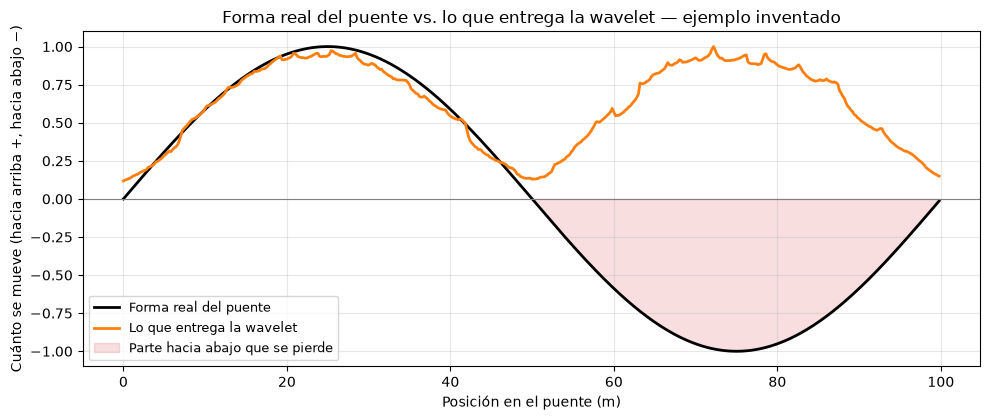

In [3]:
# Bridge shape from the wavelet: mean strength of the 1.3 Hz note at each position
band = np.abs(freqs_ssq - f_mode) <= 0.3     # only the bridge note (1.3 +/- 0.3 Hz)
shape_wavelet = np.abs(Tx[band]).mean(axis=0)
shape_wavelet /= shape_wavelet.max()         # normalized: 1 = largest movement

fig, ax = plt.subplots(figsize=(10, 4.3))
ax.plot(pos, shape_true, "k-", lw=2, label="Forma real del puente")
ax.plot(pos, shape_wavelet, color="C1", lw=2, label="Lo que entrega la wavelet")
ax.fill_between(pos, shape_true, 0, where=shape_true < 0, color="C3", alpha=0.15,
                label="Parte hacia abajo que se pierde")
ax.axhline(0, color="0.5", lw=0.8)
ax.set_xlabel("Posición en el puente (m)")
ax.set_ylabel("Cuánto se mueve (hacia arriba +, hacia abajo −)")
ax.set_title("Forma real del puente vs. lo que entrega la wavelet — ejemplo inventado")
ax.legend(loc="lower left", fontsize=9)
fig.tight_layout()
plt.show()

**Figura 2.** Forma real del puente comparada con la que entrega la wavelet (ilustrativo, datos sintéticos): la mitad que en realidad baja (de 50 a 100 m) aparece hacia arriba, porque la wavelet solo dice cuánto se mueve cada punto, no hacia qué lado.

**Ventajas**

- Sirve para vibraciones cortas y que cambian.
- Dice a la vez qué nota suena y dónde.

**Desventajas**

- Hay que saber de antemano qué nota buscar.
- Dice qué tan fuerte se mueve cada punto, pero no hacia qué lado; el dibujo sale sin la parte "hacia abajo".
- Analogía: es como saber a qué distancia está alguien de la puerta, pero no si está a la izquierda o a la derecha.
- No separa la vibración del puente de la del carro.

**Artículos:** Dabbaghchian et al. (2025).

**Entradas y salidas**

- **Entrada:** la vibración que midió el teléfono, la ubicación del carro (GPS) y la nota del puente que se quiere buscar.
- **Salida:** un mapa de colores que dice qué notas suenan y en qué punto del puente.
- **Qué se obtiene o interpreta:** en qué partes del puente vibra más esa nota y, juntando muchos viajes, la forma en que se deforma el puente, sin saber hacia qué lado.

[↑ Volver al índice](#indice)